# 04 Scaling: one server vs two

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().parent
FIGURES = ANALYSIS_DIR / 'figures'
sys.path.insert(0, str(ANALYSIS_DIR))

from scipy import stats

from src.data_loader import load_multi_node, load_single_node
from src.statistics import (
    combine_attackers,
    saturation_rate,
    slo_capacity,
    summarize,
)

plt.rcParams.update(
    {
        'figure.figsize': (7, 4),
        'figure.dpi': 110,
        'savefig.dpi': 200,
        'savefig.bbox': 'tight',
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'grid.alpha': 0.3,
    }
)
SINGLE, MULTI = '#2a78d6', '#eb6834'
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
SLOS_MS = [1, 10, 100]
single = load_single_node()
runs = combine_attackers(load_multi_node())
one = summarize(single, 'rate', ['throughput', 'lat_p99_ms', 'server_cpu'])
two = summarize(
    runs,
    ['rate', 'offered'],
    ['throughput', 'lat_p99_ms', 'node0_cpu', 'node2_cpu'],
)
if runs['n_attackers'].min() < 2:
    print(
        "WARNING: multi-node data from one attacker only; multi throughput is half the cluster's."
    )

## Capacity

In [3]:
rows = {
    'saturation': (
        saturation_rate(one),
        saturation_rate(two, offered_col='offered'),
    ),
    **{
        f'p99 <= {slo} ms': (
            slo_capacity(one, 'lat_p99_ms_mean', slo),
            slo_capacity(two, 'lat_p99_ms_mean', slo),
        )
        for slo in SLOS_MS
    },
}
capacity = pd.DataFrame(rows, index=['1 server', '2 servers']).T
capacity['speedup'] = capacity['2 servers'] / capacity['1 server']
capacity

,1 server,2 servers,speedup
saturation,18000,38000,2.111
p99 <= 1 ms,8000,16000,2.000
p99 <= 10 ms,9000,18000,2.000
p99 <= 100 ms,18000,38000,2.111


## Throughput vs total offered load

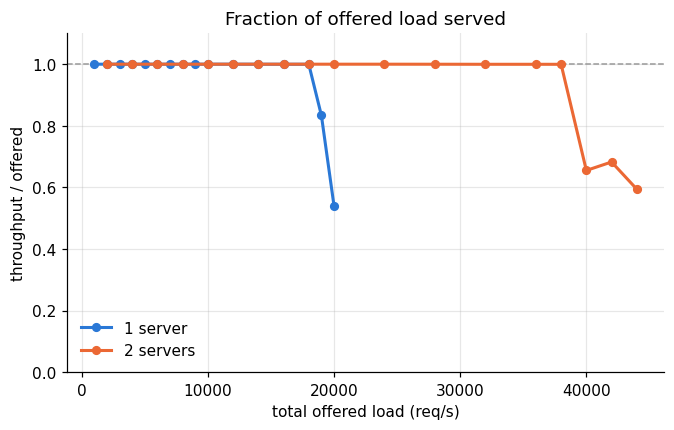

In [4]:
fig, ax = plt.subplots()
ax.axhline(1, color='0.6', ls='--', lw=1)
ax.plot(
    one['rate'],
    one['throughput_mean'] / one['rate'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    label='1 server',
)
ax.plot(
    two['rate'],
    two['throughput_mean'] / two['offered'],
    color=MULTI,
    lw=2,
    marker='o',
    ms=5,
    label='2 servers',
)
ax.set(
    xlabel='total offered load (req/s)',
    ylabel='throughput / offered',
    ylim=(0, 1.1),
    title='Fraction of offered load served',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '04_served_fraction.png')

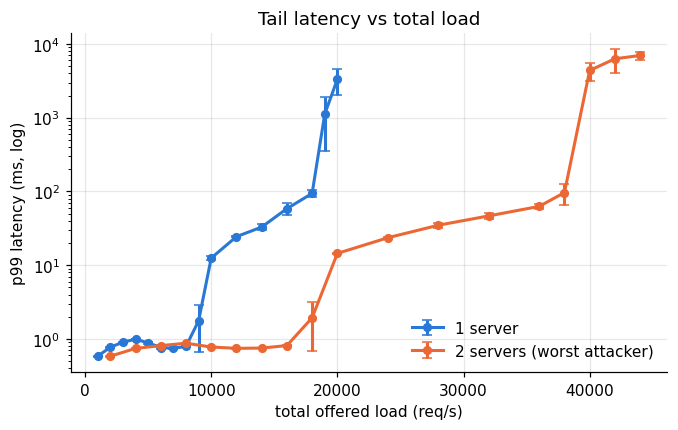

In [5]:
fig, ax = plt.subplots()
ax.errorbar(
    one['rate'],
    one['lat_p99_ms_mean'],
    yerr=one['lat_p99_ms_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='1 server',
)
ax.errorbar(
    two['rate'],
    two['lat_p99_ms_mean'],
    yerr=two['lat_p99_ms_ci95'],
    color=MULTI,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='2 servers (worst attacker)',
)
ax.set(
    yscale='log',
    xlabel='total offered load (req/s)',
    ylabel='p99 latency (ms, log)',
    title='Tail latency vs total load',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '04_p99_total_load.png')

## Per-server load

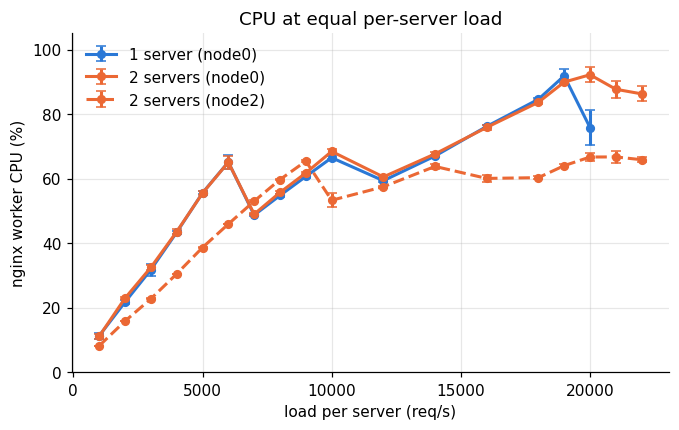

In [6]:
per_server = two.assign(per_server=two['rate'] // 2)
fig, ax = plt.subplots()
ax.errorbar(
    one['rate'],
    one['server_cpu_mean'],
    yerr=one['server_cpu_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='1 server (node0)',
)
for server, style in [('node0', '-'), ('node2', '--')]:
    ax.errorbar(
        per_server['per_server'],
        per_server[f'{server}_cpu_mean'],
        yerr=per_server[f'{server}_cpu_ci95'],
        color=MULTI,
        ls=style,
        lw=2,
        marker='o',
        ms=5,
        capsize=3,
        label=f'2 servers ({server})',
    )
ax.set(
    xlabel='load per server (req/s)',
    ylabel='nginx worker CPU (%)',
    ylim=(0, 105),
    title='CPU at equal per-server load',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '04_cpu_per_server_load.png')

In [7]:
multi_runs = runs.assign(per_server=runs['rate'] // 2)
rows = []
for rate in sorted(set(single['rate']) & set(multi_runs['per_server'])):
    a = single.loc[single['rate'] == rate, 'server_cpu']
    b = multi_runs.loc[multi_runs['per_server'] == rate, 'node0_cpu']
    t, p = stats.ttest_ind(a, b, equal_var=False)
    rows.append(
        {
            'per_server_rate': rate,
            'single': a.mean(),
            'multi': b.mean(),
            'diff': b.mean() - a.mean(),
            'p': p,
        }
    )
pd.DataFrame(rows)

,per_server_rate,single,multi,diff,p
0,1000,11.275,11.131,-0.144,0.780
1,2000,21.732,22.928,1.196,0.004
2,3000,31.758,32.461,0.703,0.426
3,4000,43.344,43.530,0.186,0.659
4,5000,55.562,55.486,-0.077,0.817
5,6000,65.111,65.052,-0.059,0.964
6,7000,48.689,48.979,0.290,0.230
7,8000,54.776,55.706,0.929,0.003
8,9000,60.661,61.753,1.092,0.000
9,10000,66.468,68.420,1.953,0.000
